## Colab Intro



## Obliczenie sumy $n$ początkowych wyrazów ciągu arytmetycznego:

  $
    S_n =\frac{a_1+a_n}{2}
    $

## Symbol Newtona:

$
  \binom{n}{k} = \frac{n!}{k!(n-k)!}
$




In [20]:
2+2

4

In [21]:
from math import pi

wynik = pi ** pi
print(wynik)

36.4621596072079


In [22]:
# Obliczenie sumy kwadratów od 1 do 100
suma_kwadratow = sum(i**2 for i in range(1, 101))
print(f"Suma kwadratów od 1 do 100 wynosi: {suma_kwadratow}")

Suma kwadratów od 1 do 100 wynosi: 338350


In [23]:
from google.colab import files

# Nazwa pliku do zapisu w środowisku Colab
sciezka_do_pliku = 'colab_wynik.txt'

try:
    # Zapisanie wyniku do pliku
    with open(sciezka_do_pliku, 'w', encoding='utf-8') as plik:
        plik.write(f"Suma kwadratów wynosi: {suma_kwadratow}\n")
    print(f"Wynik został pomyślnie zapisany w środowisku Colab jako: {sciezka_do_pliku}")

    # Pobranie zapisanego pliku na Twój komputer lokalny
    files.download(sciezka_do_pliku)
except Exception as e:
    print(f"Wystąpił błąd podczas zapisu lub pobierania pliku: {e}")

Wynik został pomyślnie zapisany w środowisku Colab jako: colab_wynik.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

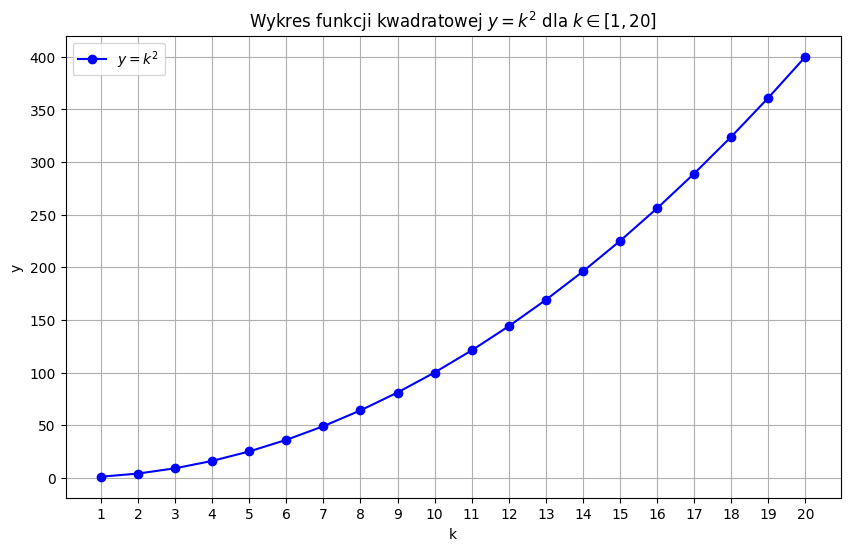

In [24]:
import matplotlib.pyplot as plt
from google.colab import files

# Definiowanie wartości k od 1 do 20
k = list(range(1, 21))
# Definiowanie wartości y = k^2
y = [val**2 for val in k]

# Tworzenie wykresu
plt.figure(figsize=(10, 6))
plt.plot(k, y, marker='o', linestyle='-', color='b', label='$y = k^2$')

# Dodanie opisu osi i tytułu (użycie raw string 'r' dla LaTeX)
plt.xlabel('k')
plt.ylabel('y')
plt.title(r'Wykres funkcji kwadratowej $y = k^2$ dla $k \in [1, 20]$')
plt.grid(True)
plt.xticks(k)
plt.legend()

# Zapisanie wykresu do pliku .png przed wyświetleniem
plt.savefig('wykres.png', dpi=300, bbox_inches='tight')

# Pobranie pliku na dysk komputera
files.download('wykres.png')

# Wyświetlenie wykresu
plt.show()

In [29]:
# Animacja wahadła matematycznego w Google Colab -> MP4
# Fizyka: pełne równanie nieliniowe  θ'' = -(g/L)·sin(θ) - b·θ'
# Całkowanie metodą Rungego-Kutty 4. rzędu. ffmpeg jest w Colabie domyślnie.

import base64
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import HTML, display

# --- Parametry fizyczne ---
G = 9.81                    # przyspieszenie ziemskie [m/s^2]
L = 1.0                     # długość wahadła [m]
TLUMIENIE = 0.15            # współczynnik tłumienia b (0 = brak tłumienia)
THETA0 = np.radians(120)    # kąt początkowy (spróbuj 10° vs 150°, żeby zobaczyć nieliniowość)
OMEGA0 = 0.0                # prędkość kątowa początkowa [rad/s]

# --- Parametry animacji ---
FPS = 30
CZAS_SEK = 10
KLATKI = FPS * CZAS_SEK
DT = 1.0 / FPS
KROKI_NA_KLATKE = 10        # podkroki całkowania dla dokładności
DLUGOSC_SLADU = 40          # ile ostatnich pozycji kulki rysować jako ślad
PLIK = "video.mp4"


def pochodne(stan):
    theta, omega = stan
    return np.array([omega, -(G / L) * np.sin(theta) - TLUMIENIE * omega])


def rk4(stan, dt):
    k1 = pochodne(stan)
    k2 = pochodne(stan + 0.5 * dt * k1)
    k3 = pochodne(stan + 0.5 * dt * k2)
    k4 = pochodne(stan + dt * k3)
    return stan + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)


# --- Symulacja: z góry liczymy kąt dla każdej klatki ---
stan = np.array([THETA0, OMEGA0])
katy = np.empty(KLATKI)
for i in range(KLATKI):
    katy[i] = stan[0]
    for _ in range(KROKI_NA_KLATKE):
        stan = rk4(stan, DT / KROKI_NA_KLATKE)

xs = L * np.sin(katy)       # pozycja kulki
ys = -L * np.cos(katy)

# --- Przygotowanie rysunku ---
fig, ax = plt.subplots(figsize=(6, 6), dpi=120)
ax.set_xlim(-1.3 * L, 1.3 * L)
ax.set_ylim(-1.3 * L, 0.4 * L)
ax.set_aspect("equal")
ax.set_title("Wahadło matematyczne")
ax.axis("off")

ax.plot([-0.3 * L, 0.3 * L], [0, 0], color="black", lw=4)            # belka mocująca
sznur, = ax.plot([], [], color="dimgray", lw=2)
slad, = ax.plot([], [], color="tab:orange", lw=1.5, alpha=0.6)
kulka, = ax.plot([], [], "o", color="tab:red", markersize=26,
                 markeredgecolor="black")
tekst = ax.text(0.02, 0.96, "", transform=ax.transAxes, va="top", family="monospace")


def aktualizuj(i):
    sznur.set_data([0, xs[i]], [0, ys[i]])
    kulka.set_data([xs[i]], [ys[i]])
    start = max(0, i - DLUGOSC_SLADU)
    slad.set_data(xs[start:i + 1], ys[start:i + 1])
    tekst.set_text(f"t = {i / FPS:5.2f} s\nθ = {np.degrees(katy[i]):7.2f}°")
    return sznur, kulka, slad, tekst


anim = FuncAnimation(fig, aktualizuj, frames=KLATKI, interval=1000 / FPS, blit=True)

# --- Zapis do MP4 ---
anim.save(PLIK, writer=FFMpegWriter(fps=FPS, bitrate=2500))
plt.close(fig)
print(f"Zapisano: {PLIK}")

# --- Podgląd w notebooku ---
with open(PLIK, "rb") as f:
    dane = base64.b64encode(f.read()).decode()

display(HTML(f"""
<video width="480" controls autoplay loop>
  <source src="data:video/mp4;base64,{dane}" type="video/mp4">
</video>
"""))

# --- (opcjonalnie) pobranie pliku na dysk ---
from google.colab import files
files.download(PLIK)

Zapisano: video.mp4


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

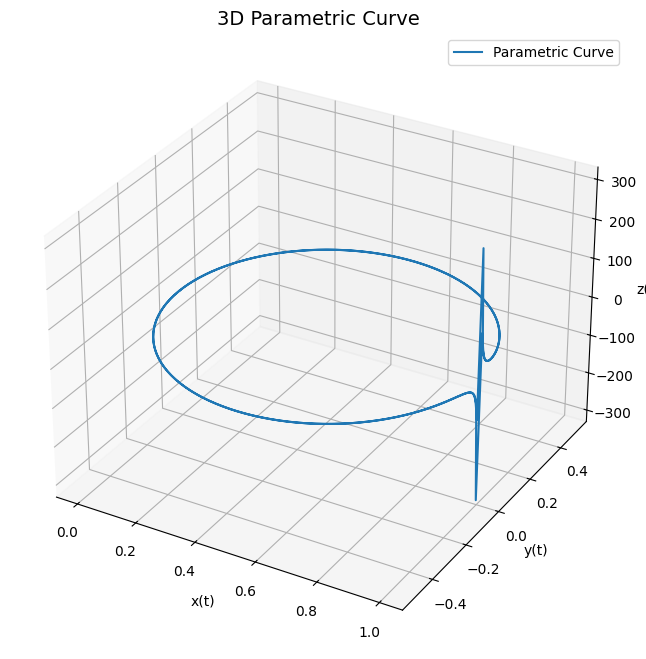

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
# Correcting the label for rendering issue in matplotlib mathtext
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

PLIK = 'parametric_curve.png'

# Parametric equations
t = np.linspace(0, 2 * np.pi, 500)
x = np.sin(t) * np.sin(t)
y = np.cos(t) * np.sin(t)
z = np.tan(t)

# 3D Plot
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.plot(x, y, z, label="Parametric Curve")
ax.set_title("3D Parametric Curve", fontsize=14)
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()
plt.show()

fig.savefig(PLIK, dpi=200, bbox_inches='tight')
plt.show()
files.download(PLIK)


Zapisano: video.gif (0.47 MB)



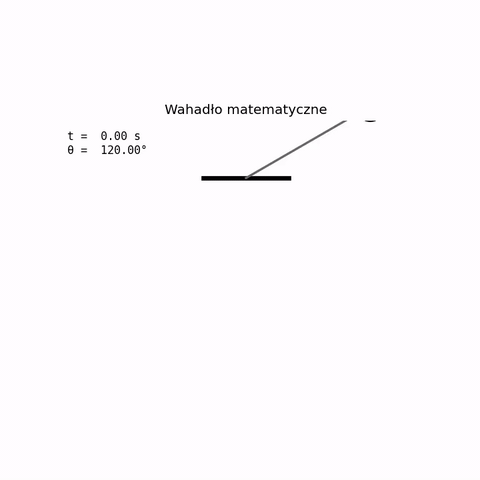

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [30]:
# Konwersja MP4 -> GIF w Google Colab (ffmpeg z własną paletą kolorów)
# Metoda z paletą (palettegen + paletteuse) daje dużo lepszą jakość GIF-a
# niż prosta konwersja domyślna.

import base64
import os
import subprocess
from IPython.display import HTML, display

# --- Ustawienia ---
PLIK_WEJSCIOWY = "video.mp4"   # plik z poprzedniego skryptu (lub własny)
PLIK_WYJSCIOWY = "video.gif"
FPS = 15                         # klatki/s w GIF-ie (mniej = mniejszy plik)
SZEROKOSC = 480                  # szerokość w pikselach, wysokość liczona automatycznie
PETLA = 0                        # 0 = zapętlenie w nieskończoność, -1 = bez pętli
CZAS_OD = None                   # np. 2.0 -> start od 2. sekundy (None = od początku)
CZAS_TRWANIA = None              # np. 5.0 -> tylko 5 sekund (None = cały film)

# --- (opcjonalnie) wgraj własny plik MP4 z komputera ---
# from google.colab import files
# wgrane = files.upload()
# PLIK_WEJSCIOWY = next(iter(wgrane))

if not os.path.exists(PLIK_WEJSCIOWY):
    raise FileNotFoundError(
        f"Nie znaleziono '{PLIK_WEJSCIOWY}'. Najpierw uruchom skrypt generujący MP4 "
        "albo wgraj plik (odkomentuj sekcję files.upload())."
    )

# --- Budowa polecenia ffmpeg ---
filtr = (
    f"fps={FPS},scale={SZEROKOSC}:-1:flags=lanczos,"
    "split[s0][s1];[s0]palettegen=stats_mode=diff[p];"
    "[s1][p]paletteuse=dither=bayer:bayer_scale=5"
)

polecenie = ["ffmpeg", "-y", "-loglevel", "error"]
if CZAS_OD is not None:
    polecenie += ["-ss", str(CZAS_OD)]
if CZAS_TRWANIA is not None:
    polecenie += ["-t", str(CZAS_TRWANIA)]
polecenie += ["-i", PLIK_WEJSCIOWY, "-vf", filtr, "-loop", str(PETLA), PLIK_WYJSCIOWY]

# --- Konwersja ---
wynik = subprocess.run(polecenie, capture_output=True, text=True)
if wynik.returncode != 0:
    raise RuntimeError(f"Błąd ffmpeg:\n{wynik.stderr}")

rozmiar_mb = os.path.getsize(PLIK_WYJSCIOWY) / 1024 / 1024
print(f"Zapisano: {PLIK_WYJSCIOWY} ({rozmiar_mb:.2f} MB)")

# --- Podgląd w notebooku ---
with open(PLIK_WYJSCIOWY, "rb") as f:
    dane = base64.b64encode(f.read()).decode()
display(HTML(f'<img src="data:image/gif;base64,{dane}" width="{SZEROKOSC}">'))

# --- (opcjonalnie) pobranie pliku na dysk ---
from google.colab import files
files.download(PLIK_WYJSCIOWY)